# 2.0 Customer-Level RFM Feature Engineering & Distribution Analysis

**Author:** Aman Singh  
**Input:** `data/interim/online_retail_cleaned.csv.gz`  
**Output:** `data/processed/customer_rfm_features.csv`  
**Production Module:** `src/features.py`

---

## 1. RFM Methodology & Scope Rules

To aggregate transactional line items into a reliable customer-level table for segmentation and churn modeling, we apply four explicit design decisions:
1. **Registered Customers Only (`Is_Registered == True`):** Unregistered `GUEST_<Invoice>` orders are single-checkout tags and cannot be tracked longitudinally across repeat visits.
2. **Merchandise Focus (`Item_Category == 'Merchandise'`):** Excludes standalone shipping/postage (`POST`, `DOT`, `C2`), discounts (`D`), and gift vouchers so RFM reflects real product purchasing behavior.
3. **Completed Orders vs. Net Spend:** `Recency_Days` and `Frequency` are computed from completed (non-cancelled) orders, while `Monetary` uses signed net revenue (`Gross_Monetary - Return_Amount`) rounded to 2 decimals. Customers with `Frequency < 1` or `Net_Monetary <= 0.01` (pure returners / floating-point dust) are excluded.
4. **Anchor Snapshot Date:** Set to `max(InvoiceDate).normalize() + 1 day` (**`2011-12-10`**) so the most recent buyers have `Recency_Days = 1`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 25)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

project_root = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.features import build_rfm_features, save_rfm_features

interim_path = project_root / 'data' / 'interim' / 'online_retail_cleaned.csv.gz'
figures_dir = project_root / 'reports' / 'figures'
processed_path = project_root / 'data' / 'processed' / 'customer_rfm_features.csv'

df_clean = pd.read_csv(interim_path)
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

reg_all = df_clean[df_clean['Is_Registered']]['Customer ID'].nunique()
reg_merch = df_clean[df_clean['Is_Registered'] & (df_clean['Item_Category'] == 'Merchandise')]['Customer ID'].nunique()
reg_comp = df_clean[df_clean['Is_Registered'] & (df_clean['Item_Category'] == 'Merchandise') & (~df_clean['Is_Cancelled'])]['Customer ID'].nunique()

print(f"Registered Customers (All Items):            {reg_all:,}")
print(f"Registered Customers (Merchandise):          {reg_merch:,}")
print(f"Registered Customers (>=1 Completed Order):  {reg_comp:,}")
print(f"Anchor Snapshot Date:                        {df_clean['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)}")

Registered Customers (All Items):            5,877
Registered Customers (Merchandise):          5,875
Registered Customers (>=1 Completed Order):  5,852
Anchor Snapshot Date:                        2011-12-10 00:00:00


**Observation:**  
Out of **`5,877`** registered customers in the cleaned interim data, **`5,875`** purchased physical merchandise, and **`5,852`** placed at least one completed (non-cancelled) order (`23` accounts only recorded cancellations during this window).

In [2]:
rfm_df = build_rfm_features(df_clean)
save_rfm_features(rfm_df, processed_path)

print(f"Final Valid RFM Customer Table: {rfm_df.shape[0]:,} customers x {rfm_df.shape[1]} features")
print(f"Nulls: {rfm_df.isna().sum().sum()} | Duplicate Customer IDs: {rfm_df['Customer ID'].duplicated().sum()}")
display(rfm_df.head(5))

Final Valid RFM Customer Table: 5,832 customers x 25 features
Nulls: 0 | Duplicate Customer IDs: 0


,Customer ID,Country,Is_UK,Recency_Days,Frequency,Monetary,Gross_Monetary,Return_Amount,Net_Units,Gross_Units,Avg_Order_Value,Unique_Products,Cancelled_Invoices,Cancellation_Rate,Tenure_Days,First_Purchase,Last_Purchase,R_Score,F_Score,M_Score,RFM_Score_Sum,RFM_Segment,Recency_Log,Frequency_Log,Monetary_Log
0,12346,United Kingdom,True,326,3,169.36,77352.96,77183.60,24,74239,25784.32,25,1,0.25,322,2010-03-02 13:08:00,2011-01-18 10:01:00,2,3,1,6,Hibernating,5.79,1.39,5.14
1,12347,Iceland,False,3,8,4921.53,4921.53,0.00,2967,2967,615.19,126,0,0.00,402,2010-10-31 14:20:00,2011-12-07 15:52:00,5,4,5,14,Champions,1.39,2.20,8.50
2,12348,Finland,False,76,5,1658.40,1658.40,0.00,2704,2704,331.68,24,0,0.00,363,2010-09-27 14:59:00,2011-09-25 13:13:00,3,4,4,11,Loyal Customers,4.34,1.79,7.41
3,12349,Italy,False,19,3,3654.54,3678.69,24.15,1616,1621,1226.23,137,1,0.25,571,2010-04-29 13:20:00,2011-11-21 09:51:00,5,3,5,13,Champions,3.00,1.39,8.20
4,12350,Norway,False,311,1,294.40,294.40,0.00,196,196,294.40,16,0,0.00,0,2011-02-02 16:01:00,2011-02-02 16:01:00,2,1,2,5,Hibernating,5.74,0.69,5.69


**Observation:**  
Filtering `Net_Monetary > 0.01` excludes the remaining `20` accounts whose completed orders were fully cancelled (`<= £0.01` net spend), yielding **`5,832` active merchandise customers** across **`25` engineered features** with **`0`** nulls and **`0`** duplicate IDs.

In [3]:
core_cols = ['Recency_Days', 'Frequency', 'Monetary', 'Avg_Order_Value', 'Tenure_Days', 'Unique_Products', 'Cancellation_Rate']
display(rfm_df[core_cols].describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]))

,Recency_Days,Frequency,Monetary,Avg_Order_Value,Tenure_Days,Unique_Products,Cancellation_Rate
count,5832.00,5832.00,5832.00,5832.00,5832.00,5832.00,5832.00
mean,200.38,6.27,2805.38,384.70,274.63,82.43,0.11
std,208.38,12.77,13847.46,1256.64,258.56,116.63,0.16
min,1.00,1.00,2.90,2.95,0.00,1.00,0.00
25%,26.00,1.00,333.79,176.60,0.00,19.00,0.00
50%,96.00,3.00,843.74,278.17,224.50,45.00,0.00
75%,379.00,7.00,2179.89,410.60,513.00,104.00,0.20
95%,624.00,20.00,8928.42,869.93,713.00,281.90,0.50
99%,726.69,46.00,26543.84,1914.66,732.00,503.38,0.53
max,739.00,373.00,578408.64,84236.25,738.00,2546.00,0.80


**Observation:**  
- **Median Customer Profile:** Buys **`3`** times (`Frequency`), spends **£843.74** net (`Monetary`), has an Average Order Value of **£278.17**, purchases **`45`** distinct SKUs (`Unique_Products`), has **`224.50` days** of tenure, and was last active **`96` days** before the snapshot date.
- **Extreme Spread:** `Frequency` reaches **`373`** orders and `Monetary` reaches **£578,408.64**, indicating strong right-skewness driven by wholesale accounts.

,Metric,Raw_Skewness,Log1p_Skewness
0,Recency_Days,0.90,-0.44
1,Frequency,12.03,1.00
2,Monetary,26.78,0.25


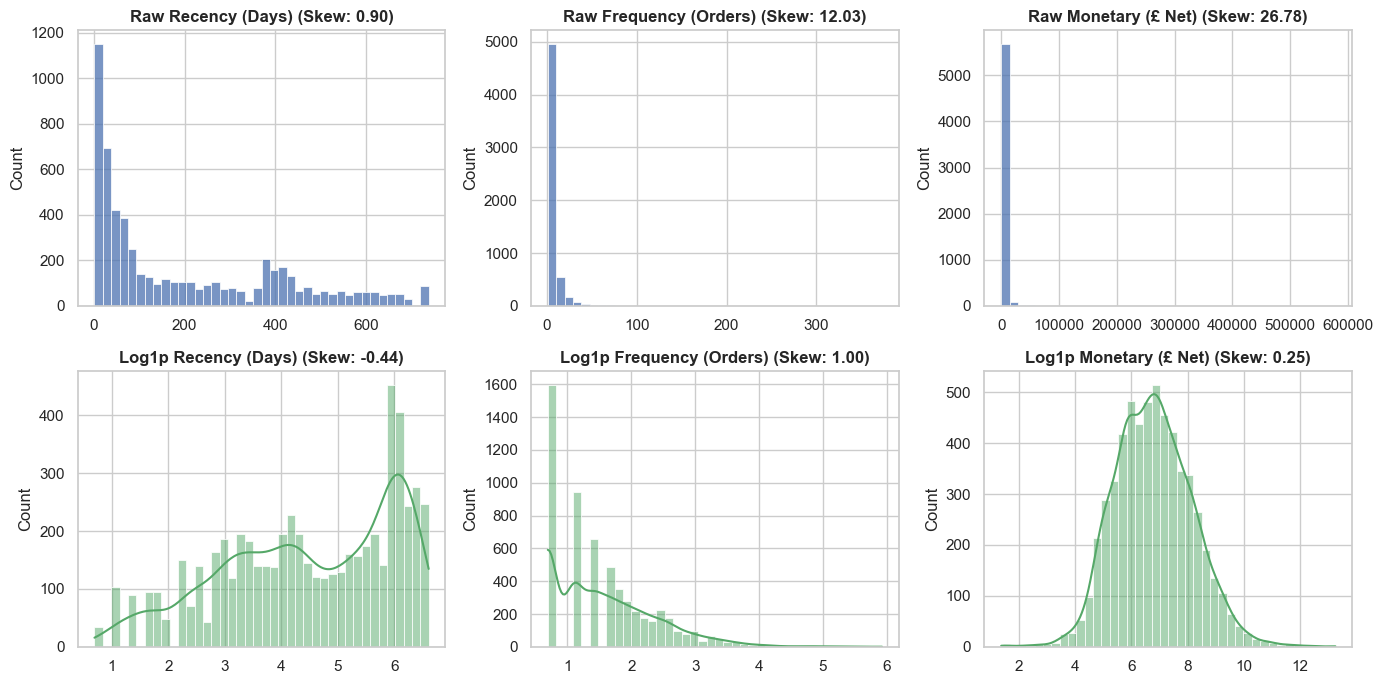

In [4]:
# Compare Raw vs Log1p Skewness and Visualize Distributions
skew_df = pd.DataFrame({
    'Metric': ['Recency_Days', 'Frequency', 'Monetary'],
    'Raw_Skewness': [rfm_df['Recency_Days'].skew(), rfm_df['Frequency'].skew(), rfm_df['Monetary'].skew()],
    'Log1p_Skewness': [rfm_df['Recency_Log'].skew(), rfm_df['Frequency_Log'].skew(), rfm_df['Monetary_Log'].skew()]
})
display(skew_df)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
pairs = [
    ('Recency_Days', 'Recency_Log', 'Recency (Days)'),
    ('Frequency', 'Frequency_Log', 'Frequency (Orders)'),
    ('Monetary', 'Monetary_Log', 'Monetary (£ Net)')
]

for col_idx, (raw_col, log_col, title) in enumerate(pairs):
    sns.histplot(rfm_df[raw_col], bins=40, ax=axes[0, col_idx], color='#4C72B0')
    axes[0, col_idx].set_title(f'Raw {title} (Skew: {rfm_df[raw_col].skew():.2f})', fontweight='bold')
    axes[0, col_idx].set_xlabel('')

    sns.histplot(rfm_df[log_col], bins=40, kde=True, ax=axes[1, col_idx], color='#55A868')
    axes[1, col_idx].set_title(f'Log1p {title} (Skew: {rfm_df[log_col].skew():.2f})', fontweight='bold')
    axes[1, col_idx].set_xlabel('')

plt.tight_layout()
fig.savefig(figures_dir / 'rfm_distributions_raw_vs_log.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:**  
Applying `np.log1p` dramatically compresses right-skewness before K-Means clustering:
- **`Frequency` skewness:** drops from **`12.03`** → **`1.00`**
- **`Monetary` skewness:** drops from **`26.78`** → **`0.25`**
- **`Recency` skewness:** shifts from **`0.90`** → **`-0.44`**

Without this log transformation, Euclidean distance in K-Means would isolate a handful of high-spend wholesalers into tiny outlier clusters instead of separating behavioral cohorts.

,RFM_Segment,Customers,Total_Revenue,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Pct,Revenue_Pct
2,Champions,1298,11373163.68,20.03,16.88,8762.07,22.26,69.51
5,Loyal Customers,830,2182706.63,79.62,6.89,2629.77,14.23,13.34
1,Cant Lose Them,250,966115.63,342.99,8.73,3864.46,4.29,5.90
0,At Risk,713,705067.46,382.71,3.06,988.87,12.23,4.31
7,Potential Loyalists,560,380076.78,26.22,2.59,678.71,9.60,2.32
6,Need Attention,385,280710.64,110.35,2.58,729.12,6.60,1.72
4,Lost,1027,263760.69,468.08,1.16,256.83,17.61,1.61
3,Hibernating,549,160406.09,316.46,1.28,292.18,9.41,0.98
8,Promising,144,31334.34,37.94,1.12,217.60,2.47,0.19
9,Recent Customers,76,17654.49,11.18,1.20,232.30,1.30,0.11


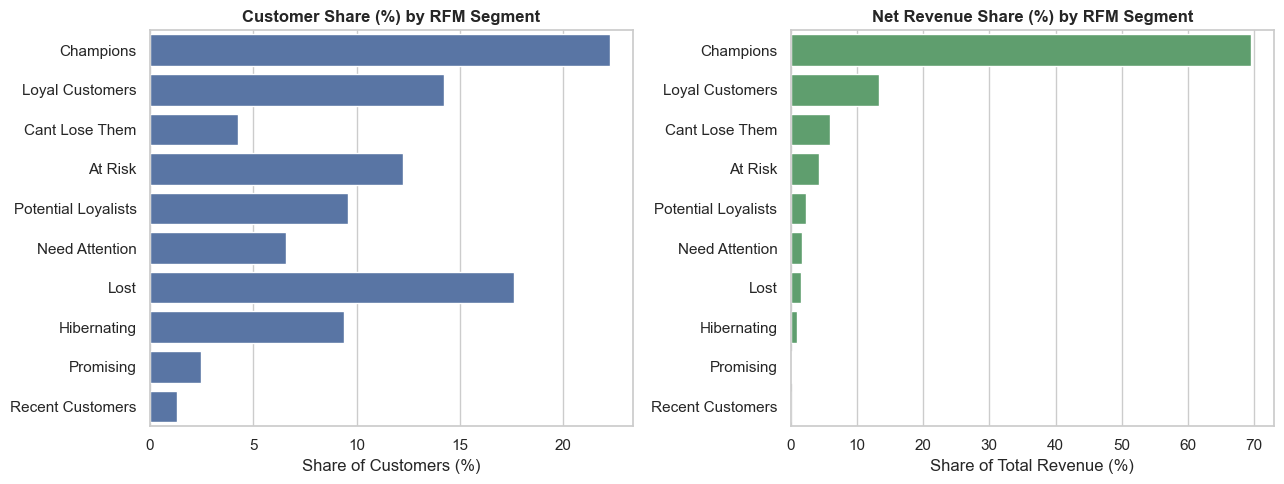

In [5]:
# Quantile RFM Segment Breakdown
seg_summary = rfm_df.groupby('RFM_Segment', as_index=False).agg(
    Customers=('Customer ID', 'count'),
    Total_Revenue=('Monetary', 'sum'),
    Avg_Recency=('Recency_Days', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean')
).sort_values('Total_Revenue', ascending=False)

seg_summary['Customer_Pct'] = (seg_summary['Customers'] / len(rfm_df)) * 100
seg_summary['Revenue_Pct'] = (seg_summary['Total_Revenue'] / seg_summary['Total_Revenue'].sum()) * 100
display(seg_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(x='Customer_Pct', y='RFM_Segment', data=seg_summary, ax=axes[0], color='#4C72B0')
axes[0].set_title('Customer Share (%) by RFM Segment', fontweight='bold')
axes[0].set_xlabel('Share of Customers (%)')
axes[0].set_ylabel('')

sns.barplot(x='Revenue_Pct', y='RFM_Segment', data=seg_summary, ax=axes[1], color='#55A868')
axes[1].set_title('Net Revenue Share (%) by RFM Segment', fontweight='bold')
axes[1].set_xlabel('Share of Total Revenue (%)')
axes[1].set_ylabel('')

plt.tight_layout()
fig.savefig(figures_dir / 'rfm_segment_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation (Rule-Based RFM Pareto Effect):**  
- **Core Revenue Engine:** **`Champions` (`1,298` customers / `22.26%`)** generate **£11,373,163.68 (`69.51%`)** of net merchandise revenue, and **`Loyal Customers` (`830` / `14.23%`)** add **£2,182,706.63 (`13.34%`)**. Together, **`36.49%`** of customers drive **`82.85%`** of revenue.
- **High-Value Churn Opportunity (`Cant Lose Them`):** **`250` high-spending customers (`4.29%`)** with an average spend of **£3,864.46** and **`8.73`** orders have been inactive for an average of **`343` days**, putting **£966,115.63 (`5.90%` of revenue)** at risk.
- **Low-Engagement Long Tail:** `Lost` (`1,027` / `17.61%`) and `Hibernating` (`549` / `9.41%`) make up **`27.02%`** of customers but contribute only **`2.59%`** of revenue.

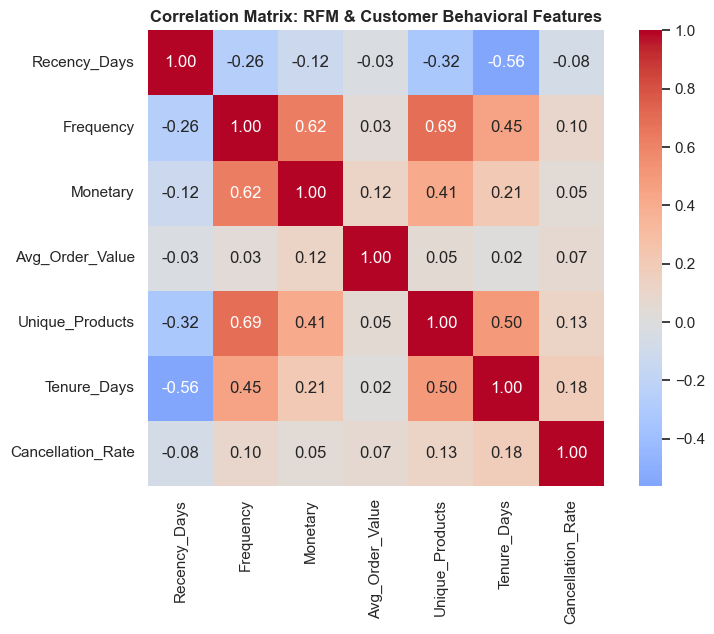

In [6]:
# Correlation Analysis across Engineered Behavioral Features
corr_cols = ['Recency_Days', 'Frequency', 'Monetary', 'Avg_Order_Value', 'Unique_Products', 'Tenure_Days', 'Cancellation_Rate']
corr_matrix = rfm_df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, ax=ax)
ax.set_title('Correlation Matrix: RFM & Customer Behavioral Features', fontweight='bold')
plt.tight_layout()
fig.savefig(figures_dir / 'rfm_feature_correlations.png', dpi=150, bbox_inches='tight')
plt.show()

**Observation:**  
- `Frequency` correlates strongly with `Unique_Products` (`0.69`) and `Monetary` (`0.62`), showing that repeat buyers broaden their SKU assortment as spend grows.
- `Recency_Days` correlates negatively with `Tenure_Days` (`-0.56`), `Unique_Products` (`-0.32`), and `Frequency` (`-0.26`), confirming that long-tenured repeat buyers purchase more recently while low-frequency accounts drift toward churn.
- **Next Step:** Standardize `Recency_Log`, `Frequency_Log`, and `Monetary_Log` with `StandardScaler` in `notebooks/3.0-customer-segmentation.ipynb` and select optimal K-Means clusters via Elbow Method and Silhouette Score.